In [ ]:
from dataloading_utils import load_into_df, TASKS
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

%load_ext autoreload
%autoreload 2

In [2]:
include_agents = True
dataset_paths = ['../gameplay_logs/humans/adults_scored_dataset','../gameplay_logs/humans/kids_scored_dataset']
if include_agents:
    dataset_paths.extend(['../gameplay_logs/AI/randomagent_logdir_noop0p475_parts','../gameplay_logs/AI/aptagent_fullview_dataset','../gameplay_logs/AI/noveldagent_fullview_dataset','../gameplay_logs/AI/rewagent_fullview_dataset'])

dataset_df = load_into_df(dataset_paths, agent_subsample=10)

loading dataset from files...
loading from path:  ../gameplay_logs/humans/adults_scored_dataset
loading from path:  ../gameplay_logs/humans/kids_scored_dataset
loading from path:  ../gameplay_logs/AI/randomagent_logdir_noop0p475_parts
loading from path:  ../gameplay_logs/AI/aptagent_fullview_dataset
loading from path:  ../gameplay_logs/AI/noveldagent_fullview_dataset
loading from path:  ../gameplay_logs/AI/rewagent_fullview_dataset
loading data into a dataframe...
computing transition tables...
adding self talk transcripts:


an example episode with filename:  20220405T183144-ach2-len188.npz
participant name:  kids_m11 , age:  9.975 , minecraft experience:  1.0
example transition: ({'facing': 'tree'}, 'do', {'facing': 'grass', 'wood': 1}) with count: 1
episode score:  1.0999999999999999
first line of self talk from this participant: " these cows do nothing. "
wordcount:  5.0  words per second:  0.006195786864931847
achievements made this episode along with count:  [('collect_wood', 4), ('wake_up', 2)]
number of actions taken this episode:  62
number of frames in this episode:  188
first frame from episode:


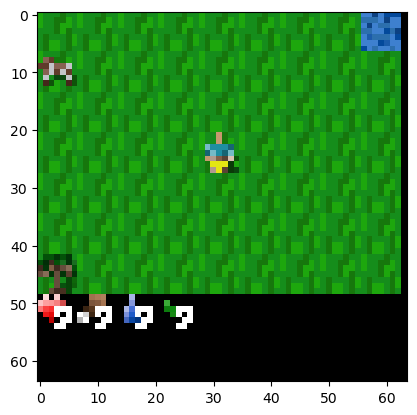

In [25]:
# Inspect the Data:
from exploration_metrics import get_unique_task_score, MAX_TASKS

for ep in kids_df.itertuples():
    if len(ep.selftalk)==0:
        continue
    print('an example episode with filename: ', ep.run)
    print('participant name: ', ep.participant, ', age: ', ep.age, ', minecraft experience: ', ep.minecraft_xp)
    print('example transition:', dataset_df.attrs['decode_transition'](list(ep.transition_table.items())[1][0]), 'with count:', list(ep.transition_table.items())[1][1])
    print('episode score: ', ep.reward.sum())
    print('first line of self talk from this participant: "', ep.selftalk[0], '"')
    print('wordcount: ', ep.wordcount, ' words per second: ', ep.WordRate)
    print('achievements made this episode along with count: ', [(item, ep.achievement_table[item])  for item in ep.achievement_table if ep.achievement_table[item] > 0])
    print('number of actions taken this episode: ', np.sum([min(i,1) for i in ep.action if i > 0]))
    print('number of frames in this episode: ', len(ep.action))
    print('first frame from episode:')
    img = Image.fromarray(ep.image[0])
    plt.imshow(img)
    break

In [ ]:
from exploration_metrics import get_unique_task_score, get_breadth_score, get_depth_score, get_map_coverage

print("###### Adding exploration performance metrics")
cumulative_achievement_breadth = []
cumulative_achievement_depth = []
cumulative_unique_achievements = []
map_coverage = [] # we dont compute cumulative map coverage since each episode is randomized
episode_achievements = []

for ep in dataset_df.itertuples():
    cumulative_achievement_breadth.append(get_breadth_score(ep.cu_achievement_table))
    cumulative_achievement_depth.append(get_depth_score(ep.cu_achievement_table))
    cumulative_unique_achievements.append(get_unique_task_score(ep.cu_achievement_table))
    map_coverage.append(get_map_coverage(ep.map_coverage_table))
    episode_achievements.append(get_unique_task_score(ep.achievement_table))
    
dataset_df.insert(1,'cu_breadth_score',cumulative_achievement_breadth)
dataset_df.insert(1,'cu_depth_score',cumulative_achievement_depth)
dataset_df.insert(1,'cu_achievement_score',cumulative_unique_achievements)
dataset_df.insert(1,'map_coverage', map_coverage)
dataset_df.insert(1,'ep_achievement_score', episode_achievements)

In [ ]:
m11_df = dataset_df[dataset_df['participant'].str.contains('kids_m11')]
print("Participant M11 Mean Achievement Score: ", m11_df['ep_achievement_score'].mean())
print("Participant M11 Overall Achievement Score: ", m11_df['cu_achievement_score'].iloc[-1])
print("Participant M11 Overall Breadth Score: ", m11_df['cu_breadth_score'].iloc[-1])
print("Participant M11 Overall Depth Score: ", m11_df['cu_depth_score'].iloc[-1])
print("Participant M11 Map Coverage Score: ", m11_df['map_coverage'].mean())

Participant M11 Mean Achievement Score:  0.2994652406417112
Participant M11 Overall Achievement Score:  0.6470588235294118
Participant M11 Overall Breadth Score:  0.35294117647058826
Participant M11 Overall Depth Score:  0.8333333333333334
Participant M11 Map Coverage Score:  0.3380681818181818


In [15]:
import input_entropy, info_gain_log_counts, empowerment

print("####### Calculating Information-Theoretic Measures...")
entropies,info_gains = [],[]
for ep in dataset_df.itertuples():
    entropies.append(input_entropy.compute_entropy(ep.cu_transition_table))
    info_gains.append(info_gain_log_counts.compute_cu_infogain(ep.transition_table, ep.cu_transition_table))
dataset_df['entropy']=entropies/max(entropies)
dataset_df['info_gain']=info_gains/max(info_gains)

# note this is quite slow 
import warnings
warnings.filterwarnings('ignore') 
all_empowerments=[]

empowerments = []
for ep in dataset_df.itertuples():
    empowerments.append(empowerment.compute_empowerment(ep.cu_transition_table))
all_empowerments.append(empowerments)
dataset_df['empowerment']=empowerments/max(empowerments)

####### Calculating Info Theoretic Measures


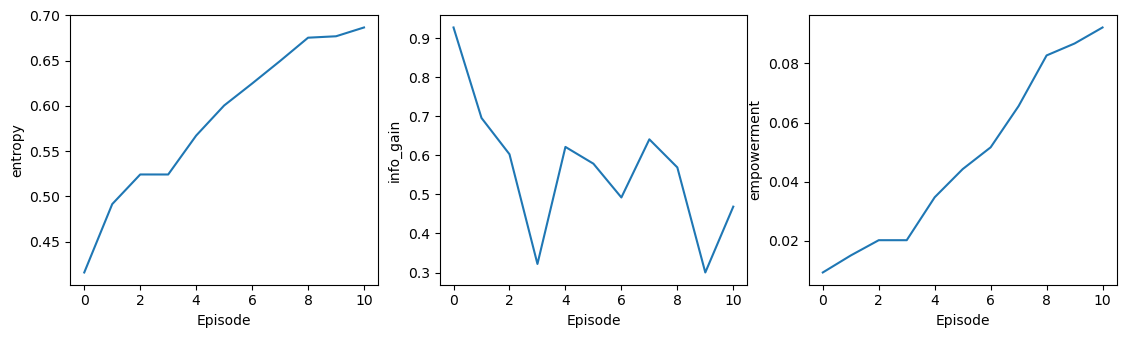

In [46]:
part_df = dataset_df[dataset_df['participant'].str.contains('kids_m11')]
fig, axs = plt.subplots(1, 3, figsize = (3*4.5, 3.5))
for ax,measure in zip(axs, ['entropy', 'info_gain', 'empowerment']):
    ax.set_xlabel('Episode')
    ax.plot(np.arange(len(part_df.groupby('run'))), part_df.groupby('run')[measure].last())
    ax.set_ylabel(measure)

In [50]:
kids_df = dataset_df[dataset_df['participant'].str.contains('kids')]
adults_df = dataset_df[dataset_df['participant'].str.contains('adults')]
random_df = dataset_df[dataset_df['participant'].str.contains('random')]
rewagent_df = dataset_df[dataset_df['participant'].str.contains('rewagent')]
noveldagent_df = dataset_df[dataset_df['participant'].str.contains('noveldagent')]
aptagent_df = dataset_df[dataset_df['participant'].str.contains('aptagent')]

In [55]:
import pickle 
with open('../transcripts/selftalk_annotations.pkl', 'rb') as f:
    selftalk_annotations = pickle.load(f)
for annotation_type in ['question_fraction','goal_fraction']:
    annotation_dict = {key: value[annotation_type] for key,value in selftalk_annotations.items()}
    print("Fraction of utterances mentioning " + annotation_type.split('_')[0] + "s for each participant: ")
    print(annotation_dict)

Fraction of utterances mentioning questions for each participant: 
{'adults_part1': 0.12682926829268293, 'adults_part10': 0.4, 'adults_part11': 0.0, 'adults_part12': 0, 'adults_part13': 0, 'adults_part14': 0, 'adults_part15': 0.0, 'adults_part16': 0, 'adults_part17': 0.13157894736842105, 'adults_part18': 0.11538461538461539, 'adults_part19': 0.5, 'adults_part2': 0.5, 'adults_part20': 0.16666666666666666, 'adults_part22': 0.08695652173913043, 'adults_part23': 0, 'adults_part24': 0, 'adults_part3': 0.05263157894736842, 'adults_part4': 0.2, 'adults_part5': 0.0, 'adults_part6': 0.1, 'adults_part7': 0, 'adults_part8': 0.0, 'adults_part9': 0, 'kids_m1': 0, 'kids_m10': 0, 'kids_m11': 0.0, 'kids_m12': 0.0, 'kids_m13': None, 'kids_m14': 0.21739130434782608, 'kids_m15': 0.06666666666666667, 'kids_m16': 0.06666666666666667, 'kids_m17': 0.0, 'kids_m18': None, 'kids_m19': None, 'kids_m2': None, 'kids_m20': None, 'kids_m21': None, 'kids_m22': None, 'kids_m23': None, 'kids_m24': None, 'kids_m25': 0.1